# Comprehensive Guide to Seaborn Data Visualization

### Why Seaborn?
Seaborn is a powerful Python data visualization library built on top of **Matplotlib**, tightly integrated with **Pandas DataFrames** and **NumPy** data structures.

**Key Advantages:**
1. **High-Level Abstraction**: Complex statistical plots require only a single line of code instead of dozens of lines of Matplotlib boilerplate.
2. **Superior Aesthetics**: Modern, publication-ready default color palettes, grid styles, and font rendering.
3. **Automated Statistical Estimation**: Automatically calculates and plots aggregations (mean, median, standard deviation) and 95% bootstrap confidence intervals.
4. **Rich Specialized Visualizations**: Includes advanced statistical graphs out of the box (e.g., KDE plots, violin plots, pairplots, joint grids, faceting grids, and hierarchical cluster maps).
5. **Seamless Pandas Integration**: Directly accepts DataFrame columns by string name without needing manual array slicing or grouping.

### Seaborn Roadmap

#### Types of Functions: Figure-Level vs. Axis-Level

| Feature | Axis-Level Functions | Figure-Level Functions |
| :--- | :--- | :--- |
| **Matplotlib Object** | Draws onto a single `matplotlib.axes.Axes` | Manages an entire figure via a Seaborn Grid (`FacetGrid`) |
| **Custom Subplots (`ax=`)** | Supports `ax=ax` for embedding in Matplotlib subplots | Does **not** accept `ax=` (creates its own figure canvas) |
| **Multi-Plot Faceting** | Requires manual `plt.subplots()` loops | Built-in faceting via `col`, `row`, and `col_wrap` |
| **Sizing Control** | Sized via Matplotlib `plt.figure(figsize=(w, h))` | Sized via `height` and `aspect` parameters |
| **Return Value** | `AxesSubplot` object | `FacetGrid` object |
| **Examples** | `scatterplot()`, `lineplot()`, `histplot()`, `boxplot()` | `relplot()`, `displot()`, `catplot()`, `lmplot()` |

---

#### Main Plot Classifications in Seaborn:
1. **Relational Plots**: Visualizes statistical relationships between continuous variables (`scatterplot`, `lineplot`, `relplot`).
2. **Distribution Plots**: Examines data spread, frequency, probability density, and modality (`histplot`, `kdeplot`, `rugplot`, `displot`).
3. **Categorical Plots**: Analyzes categorical vs. continuous data (`stripplot`, `swarmplot`, `boxplot`, `violinplot`, `barplot`, `pointplot`, `countplot`, `catplot`).
4. **Regression Plots**: Visualizes linear relationships, best-fit lines, and model residuals (`regplot`, `lmplot`, `residplot`).
5. **Matrix Plots**: 2D color-encoded grids for correlation matrices and pivot tables (`heatmap`, `clustermap`).
6. **Multiplots / Grids**: Multi-panel layouts conditioned on variables (`FacetGrid`, `PairGrid`, `JointGrid`).

Official Documentation: https://seaborn.pydata.org/api.html

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
tips = sns.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [4]:
# load iris dataset
iris = sns.load_dataset('iris')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 1. Relational Plot

Relational plots explore the statistical relationship between two or more numeric/continuous variables (**bivariate analysis**).

#### Functions:
- **`sns.scatterplot()`** (Axes-level): Plots individual observation points on a Cartesian plane.
- **`sns.lineplot()`** (Axes-level): Draws a continuous line connecting points, ideal for trends and time series.
- **`sns.relplot()`** (Figure-level): The unified figure-level interface for relational plotting (`kind="scatter"` or `kind="line"`).

#### Core Semantic Parameters:
- **`x`, `y`**: Variables specifying positions along the horizontal and vertical axes.
- **`hue`**: Groups data points by color according to a categorical or numerical variable.
- **`style`**: Groups data points by marker shape or line dash pattern.
- **`size`**: Modulates the area of marker points or thickness of lines based on a variable.
- **`col` / `row`** *(relplot only)*: Organizes subplots into columns/rows based on category levels without writing loops.

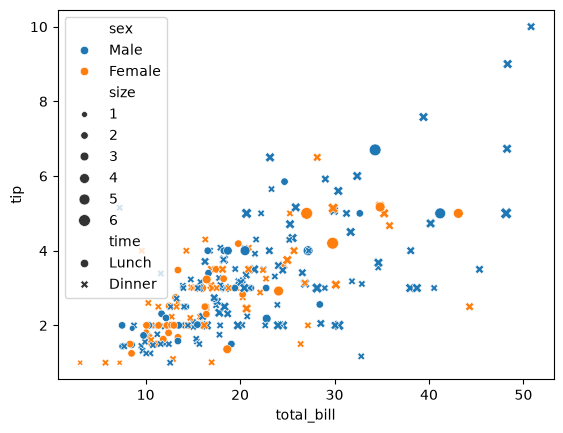

In [5]:
# scatter plot -> axes level function
sns.scatterplot(data=tips, x='total_bill', y='tip',hue='sex',style='time',size='size')
plt.show()

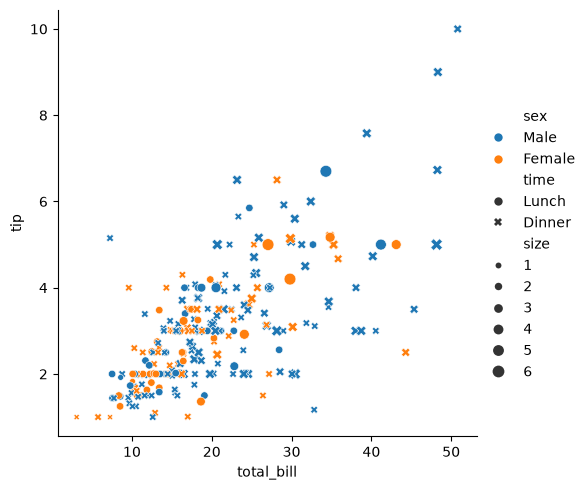

In [6]:
# relplot -> figure level -> square shape
sns.relplot(data=tips, x='total_bill', y='tip', kind='scatter',hue='sex',style='time',size='size')
plt.show()

In [7]:
# line plot
gap = px.data.gapminder()
temp_df = gap[gap['country'] == 'India']
temp_df

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
696,India,Asia,1952,37.373,372000000,546.565749,IND,356
697,India,Asia,1957,40.249,409000000,590.061996,IND,356
698,India,Asia,1962,43.605,454000000,658.347151,IND,356
699,India,Asia,1967,47.193,506000000,700.770611,IND,356
700,India,Asia,1972,50.651,567000000,724.032527,IND,356
701,India,Asia,1977,54.208,634000000,813.337323,IND,356
702,India,Asia,1982,56.596,708000000,855.723538,IND,356
703,India,Asia,1987,58.553,788000000,976.512676,IND,356
704,India,Asia,1992,60.223,872000000,1164.406809,IND,356
705,India,Asia,1997,61.765,959000000,1458.817442,IND,356


<Axes: xlabel='year', ylabel='lifeExp'>

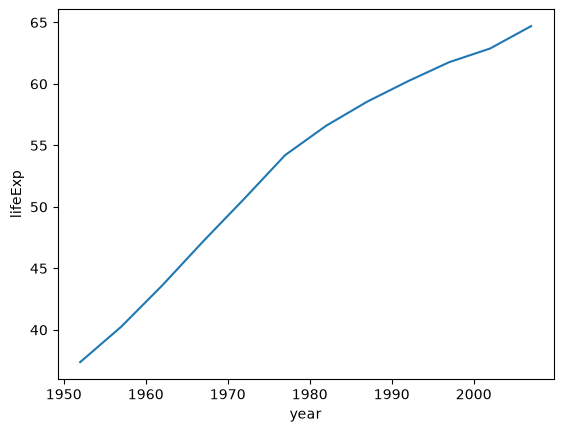

In [8]:
# axes level function
sns.lineplot(data=temp_df, x='year', y='lifeExp')

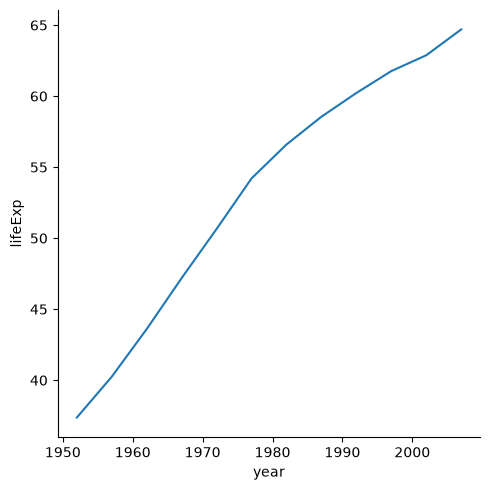

In [9]:
# relplot -> figure level -> square shape
sns.relplot(data=temp_df, x='year', y='lifeExp', kind='line')
plt.show()

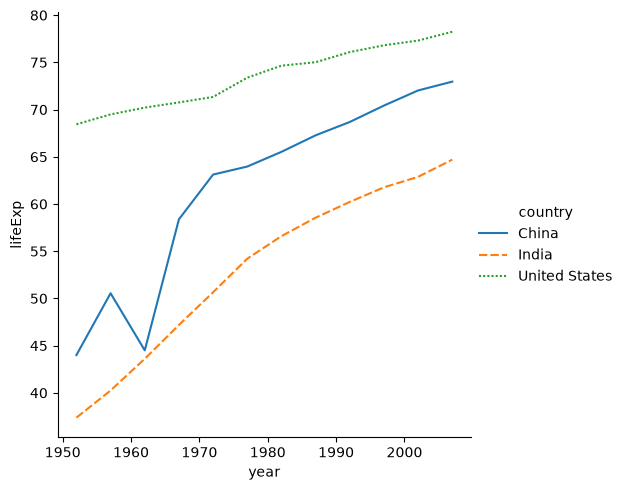

In [10]:
# multiple lines using hue and style
temp_df_multi = gap[gap['country'].isin(['India', 'China', 'United States'])]
sns.relplot(data=temp_df_multi, x='year', y='lifeExp', kind='line', hue='country', style='country')
plt.show()

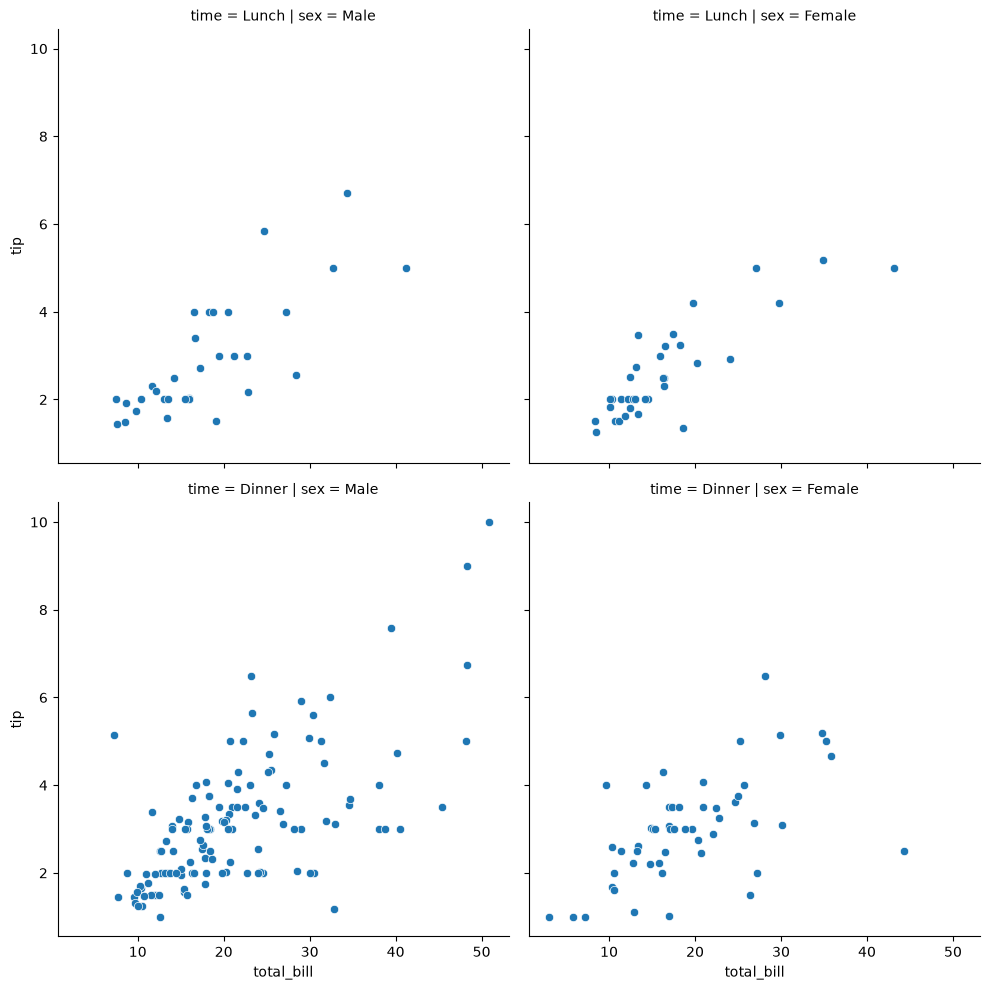

In [11]:
# faceting with relplot using col and row
sns.relplot(data=tips, x='total_bill', y='tip', kind='scatter', col='sex', row='time')
plt.show()

### 2. Distribution Plot

Distribution plots examine the distribution, spread, central tendency, skewness, and outliers of numerical data (**univariate and bivariate analysis**).

#### Functions:
- **`sns.histplot()`** (Axes-level): Groups continuous values into discrete bins and plots frequency counts or probabilities.
  - Key Parameters: `bins` (number of bins), `binwidth`, `kde=True` (overlays smooth density curve), `element="step"`.
- **`sns.kdeplot()`** (Axes-level): Kernel Density Estimation – non-parametric estimation of the continuous Probability Density Function (PDF).
  - Key Parameters: `fill=True` (shades area under curve), `bw_adjust` (adjusts smoothing bandwidth).
- **`sns.rugplot()`** (Axes-level): Draws small vertical tick marks on the axis for every single data point; often paired with histograms/KDEs to display raw sample density.
- **Bivariate Distribution (2D KDE / 2D Hist)**: Shows joint distribution contours between two continuous variables.
- **`sns.displot()`** (Figure-level): Unified interface for distribution plotting (`kind="hist"`, `kind="kde"`, or `kind="ecdf"`), supporting `col` and `row` faceting.

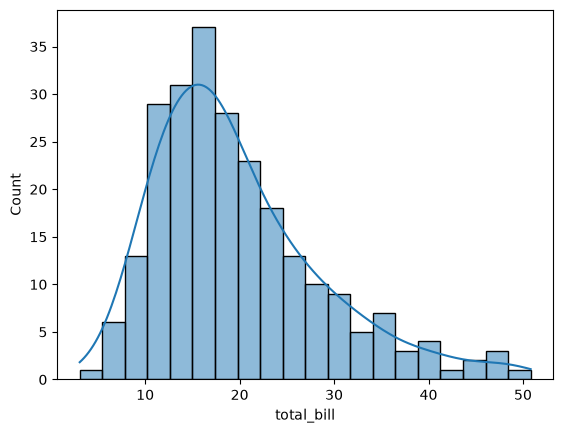

In [12]:
# histplot -> axes level function
sns.histplot(data=tips, x='total_bill', bins=20, kde=True)
plt.show()

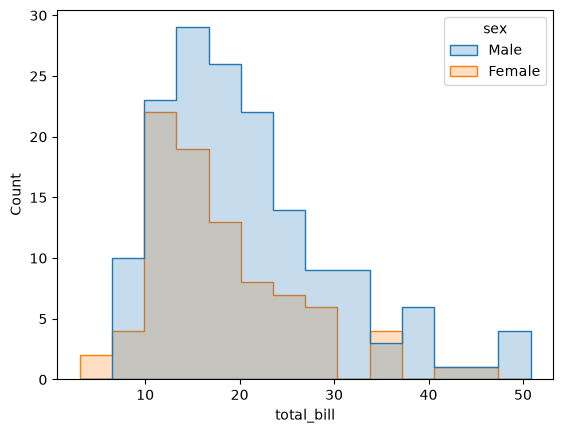

In [13]:
# histplot with hue
sns.histplot(data=tips, x='total_bill', hue='sex', element='step')
plt.show()

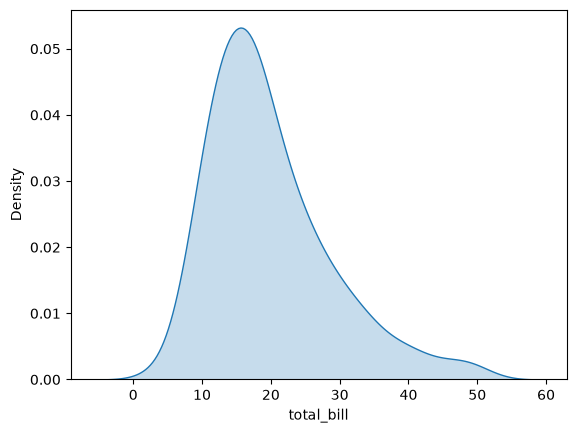

In [14]:
# kdeplot -> Kernel Density Estimation
sns.kdeplot(data=tips, x='total_bill', fill=True)
plt.show()

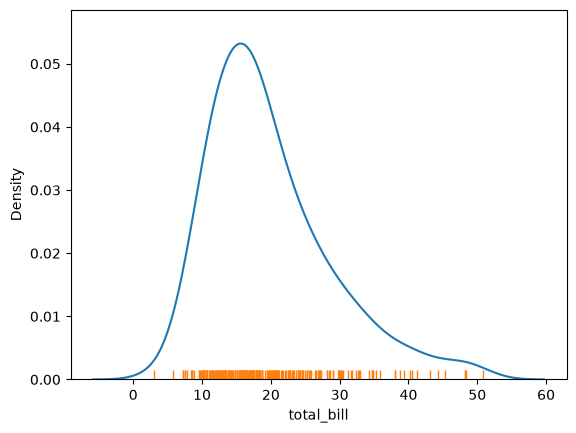

In [15]:
# rugplot -> marginal marks showing individual data points
sns.kdeplot(data=tips, x='total_bill')
sns.rugplot(data=tips, x='total_bill')
plt.show()

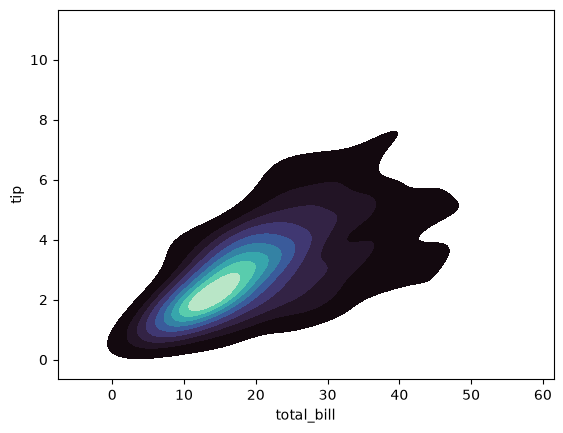

In [16]:
# Bivariate distribution plot (2D KDE plot)
sns.kdeplot(data=tips, x='total_bill', y='tip', fill=True, cmap='mako')
plt.show()

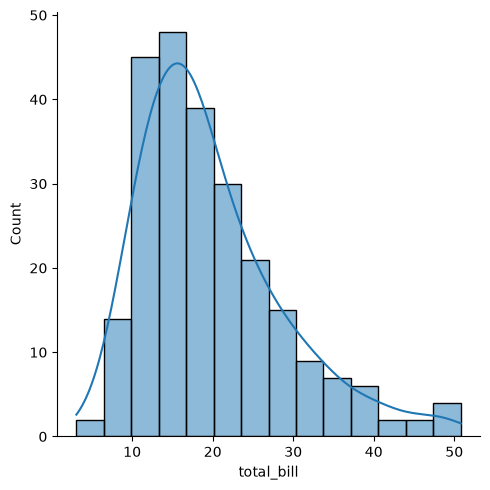

In [17]:
# displot -> figure level function (histogram with KDE)
sns.displot(data=tips, x='total_bill', kind='hist', kde=True)
plt.show()

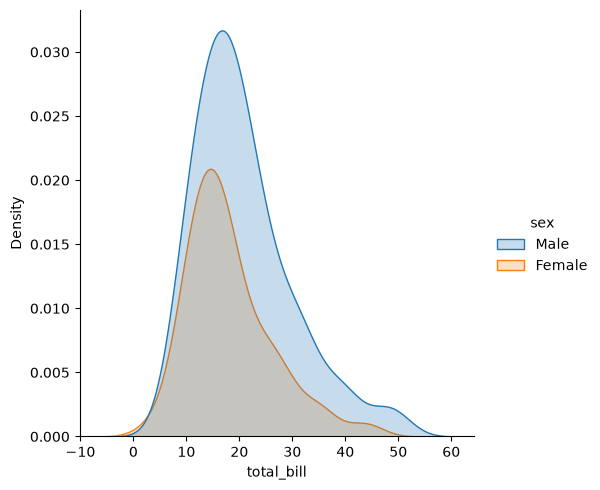

In [18]:
# displot with kind="kde" and hue
sns.displot(data=tips, x='total_bill', kind='kde', hue='sex', fill=True)
plt.show()

### 3. Categorical Plots

Categorical plots are used when at least one variable is discrete/categorical and the other is numerical. They compare data distributions, counts, or central tendencies across groups.

#### Main Categories of Categorical Plots:
1. **Categorical Scatter Plots**:
   - **`sns.stripplot()`**: Scatter plot where one axis is categorical. Uses `jitter=True` to displace overlapping points horizontally for clearer visibility.
   - **`sns.swarmplot()`**: Non-overlapping categorical scatter plot (beeswarm plot). Points are automatically shifted along the categorical axis so that no points overlap. Best for small-to-medium datasets.
2. **Categorical Distribution Plots**:
   - **`sns.boxplot()`**: Displays the 5-number summary (Min, Q1, Median, Q3, Max) and identifies outliers (> 1.5 * IQR).
   - **`sns.violinplot()`**: Combines a box plot with a rotated Kernel Density Estimation (KDE) curve on both sides, revealing multimodal distributions and skewness (`split=True` for binary hue comparisons).
3. **Categorical Estimate Plots (Central Tendency)**:
   - **`sns.barplot()`**: Represents an aggregated summary statistic (default: mean) as bar heights with vertical error bars indicating confidence intervals. Use `estimator=...` (e.g. `np.median`, `np.min`, `len`) to customize.
   - **`sns.pointplot()`**: Displays point estimates and confidence intervals connected by lines, making it easy to identify trend slopes, interactions, and rate of change across categories.
   - **`sns.countplot()`**: A specialized bar plot that counts the number of observations in each category (frequency table visualization).
4. **Figure-Level Wrapper**:
   - **`sns.catplot()`**: Master figure-level function taking `kind="strip" | "swarm" | "box" | "violin" | "bar" | "point" | "count"`, with multi-plot grid faceting (`col`, `row`).

<Axes: xlabel='total_bill', ylabel='tip'>

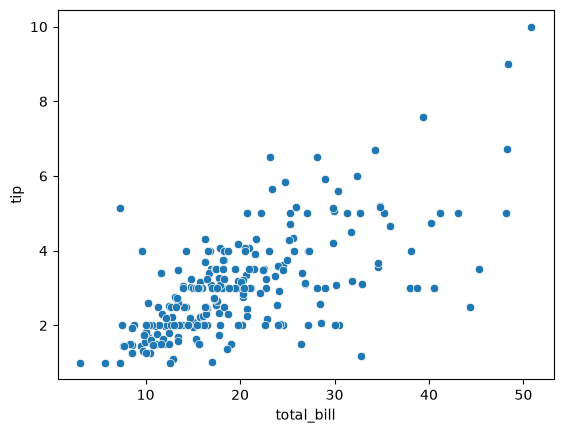

In [19]:
sns.scatterplot(data=tips, x='total_bill',y='tip')

<Axes: xlabel='day', ylabel='total_bill'>

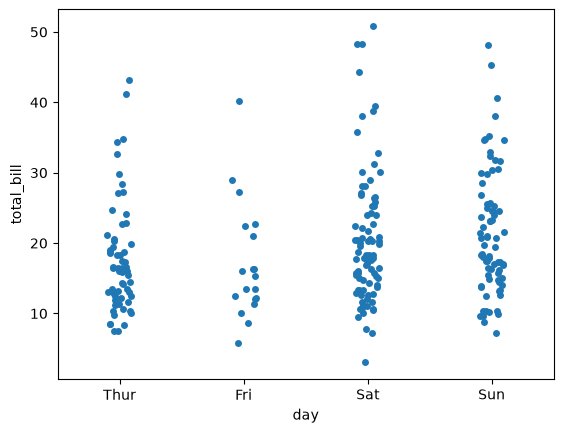

In [20]:
# strip plot
# axes level function
sns.stripplot(data=tips,x='day',y='total_bill')

<Axes: xlabel='day', ylabel='total_bill'>

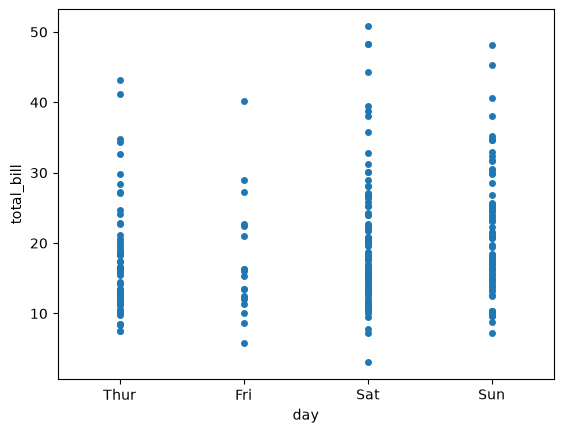

In [21]:
sns.stripplot(data=tips,x='day',y='total_bill', jitter=False)

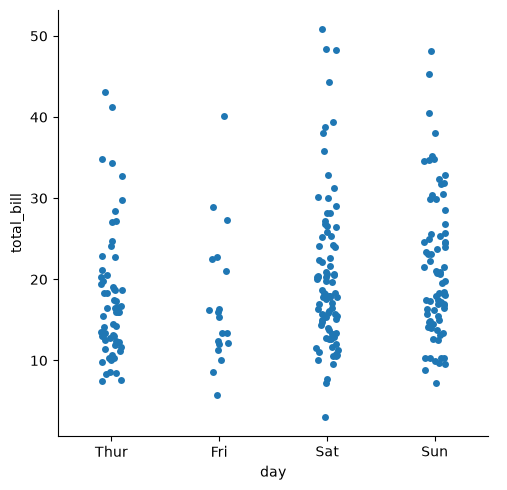

In [22]:
# using catplot
# figure level function
sns.catplot(data=tips, x='day',y='total_bill',kind='strip')

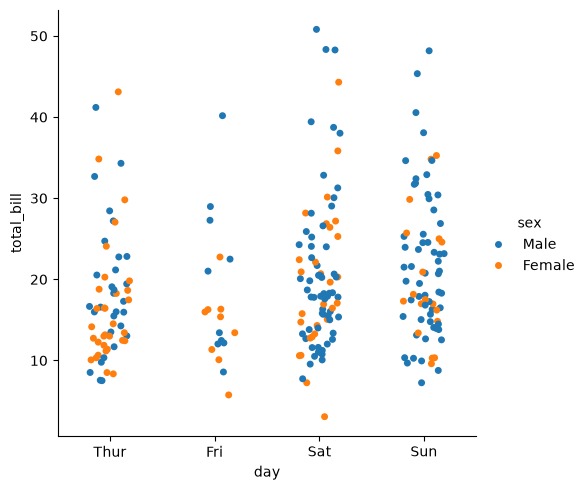

In [23]:
# jitter
sns.catplot(data=tips, x='day',y='total_bill',kind='strip',jitter=0.2,hue='sex')

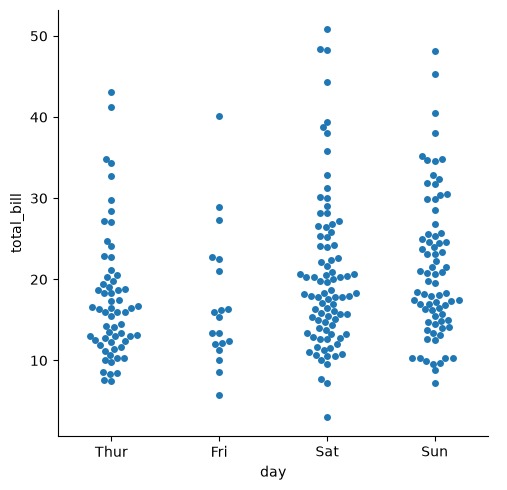

In [24]:
# swarmplot
sns.catplot(data=tips, x='day',y='total_bill',kind='swarm')

<Axes: xlabel='day', ylabel='total_bill'>

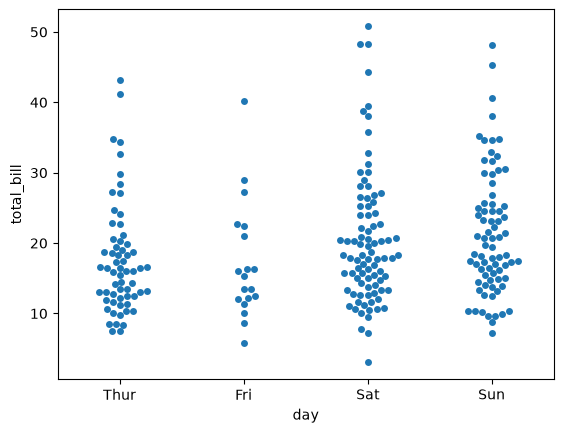

In [25]:
sns.swarmplot(data=tips, x='day',y='total_bill')

<Axes: xlabel='day', ylabel='total_bill'>

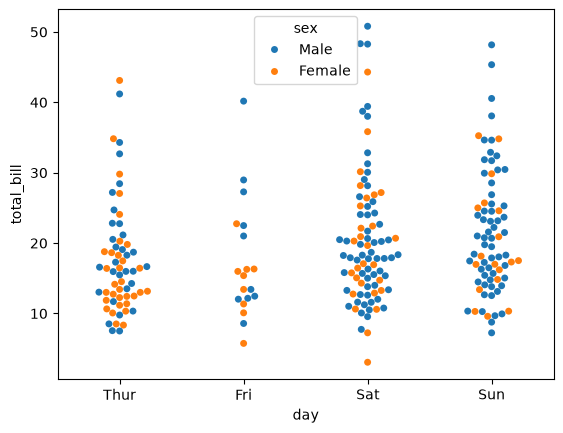

In [26]:
# hue
sns.swarmplot(data=tips, x='day',y='total_bill',hue='sex')

### Boxplot

A **boxplot** is a standardized way of displaying the distribution of data based on a five-number summary:
- **Minimum**: $Q_1 - 1.5 \times \text{IQR}$ (lowest datum within 1.5 IQR of lower quartile)
- **First Quartile ($Q_1$ / 25th percentile)**: 25% of data falls below this value
- **Median ($Q_2$ / 50th percentile)**: The middle value of the dataset
- **Third Quartile ($Q_3$ / 75th percentile)**: 75% of data falls below this value
- **Maximum**: $Q_3 + 1.5 \times \text{IQR}$ (highest datum within 1.5 IQR of upper quartile)
- **Outliers**: Data points plotted as individual dots beyond the whiskers ($> 1.5 \times \text{IQR}$).

<Axes: xlabel='day', ylabel='total_bill'>

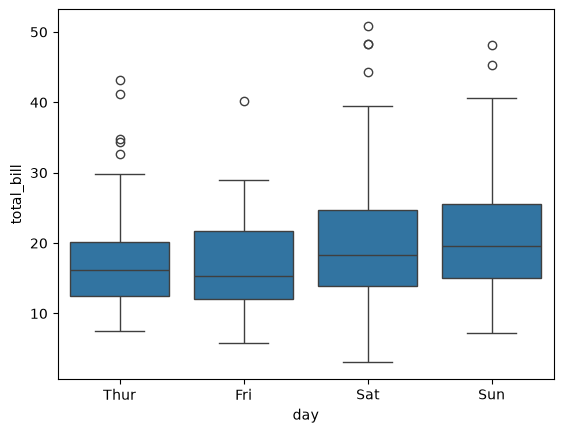

In [27]:
# Box plot
sns.boxplot(data=tips,x='day',y='total_bill')

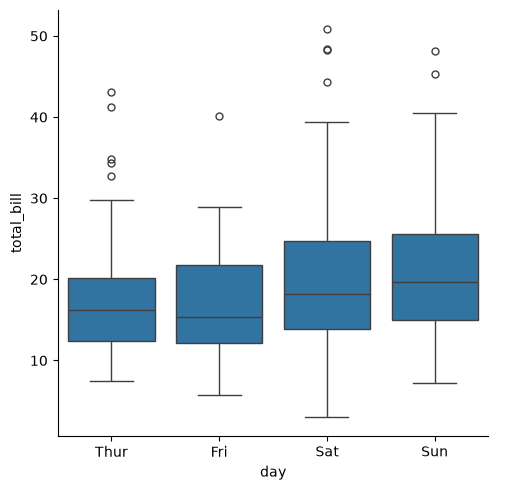

In [28]:
# Using catplot
sns.catplot(data=tips,x='day',y='total_bill',kind='box')

<Axes: xlabel='day', ylabel='total_bill'>

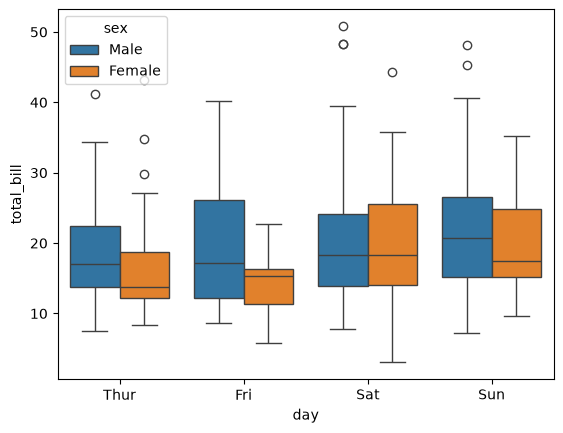

In [29]:
# hue
sns.boxplot(data=tips,x='day',y='total_bill',hue='sex')

<Axes: ylabel='total_bill'>

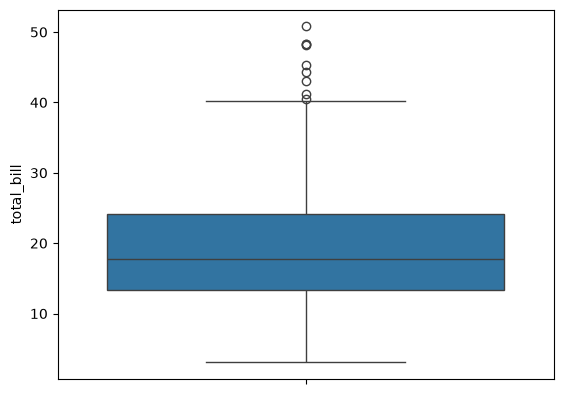

In [30]:
# single boxplot -> numerical col
sns.boxplot(data=tips,y='total_bill')

### Violinplot = (Boxplot + KDEplot)

A **violinplot** plays a similar role to a box-and-whisker plot, but it also shows the **probability density** of the data at different values using a Kernel Density Estimation (KDE) curve on both sides.
- Features: Shows multimodal distributions (peaks), symmetry, and data spread.
- `split=True`: When using a binary `hue` (e.g. Sex: Male/Female), it draws one half of the violin for each category on the same plot, saving space and making direct comparison easier.

<Axes: xlabel='day', ylabel='total_bill'>

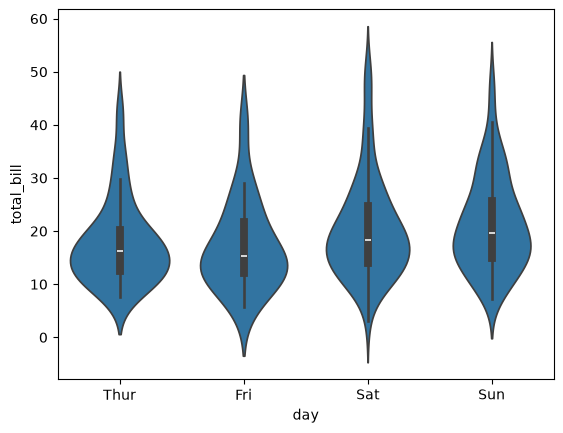

In [31]:
# violinplot
sns.violinplot(data=tips,x='day',y='total_bill')

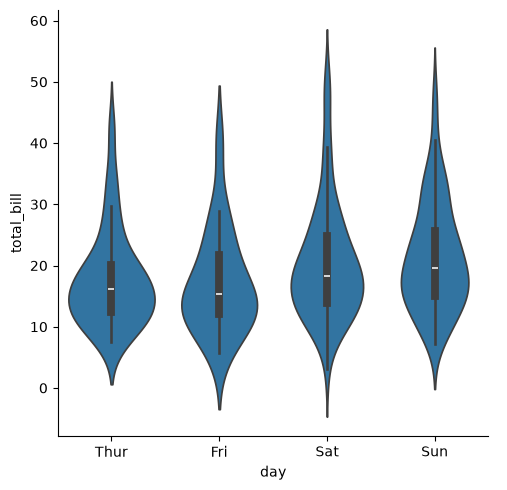

In [32]:
sns.catplot(data=tips,x='day',y='total_bill',kind='violin')

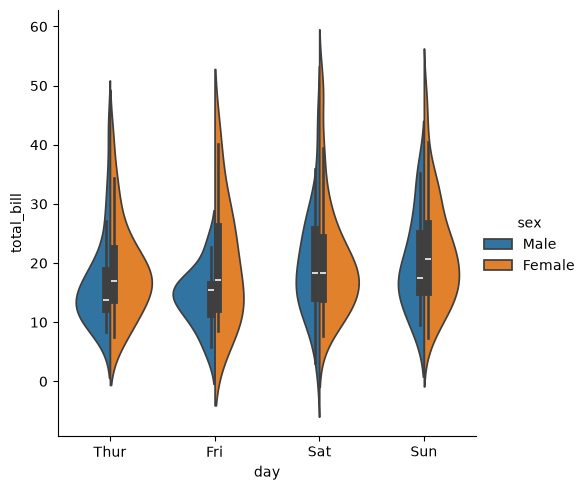

In [33]:
# hue

sns.catplot(data=tips,x='day',y='total_bill',kind='violin',hue='sex',split=True)

<Axes: xlabel='sex', ylabel='total_bill'>

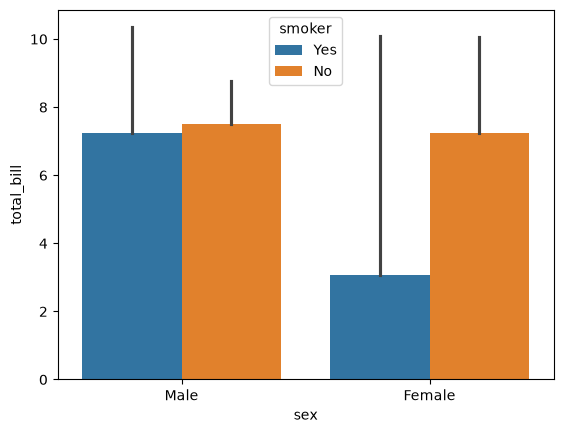

In [34]:
# barplot
# some issue with errorbar
import numpy as np
sns.barplot(data=tips, x='sex', y='total_bill',hue='smoker',estimator=np.min)

/var/folders/qh/gj7grb5121zdf7b2nvgr37km0000gn/T/ipykernel_21758/3522951494.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=tips, x='sex', y='total_bill',ci=None)


<Axes: xlabel='sex', ylabel='total_bill'>

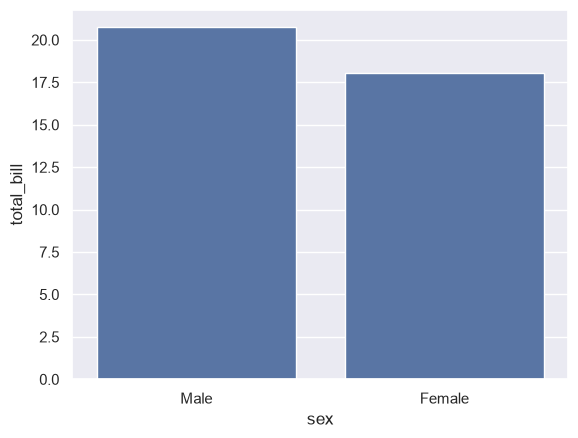

In [62]:
sns.barplot(data=tips, x='sex', y='total_bill',ci=None)

/var/folders/qh/gj7grb5121zdf7b2nvgr37km0000gn/T/ipykernel_21758/2657825262.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.pointplot(data=tips, x='sex', y='total_bill',hue='smoker',ci=None)


<Axes: xlabel='sex', ylabel='total_bill'>

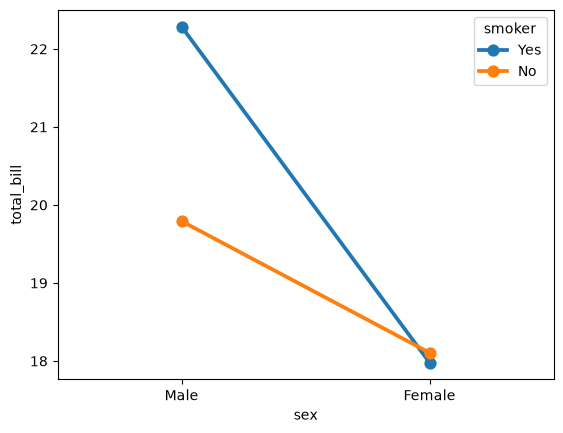

In [36]:
# point plot
sns.pointplot(data=tips, x='sex', y='total_bill',hue='smoker',ci=None)

### Statistical Bootstrapping & Confidence Intervals

When there are multiple observations in each category, Seaborn automatically uses **bootstrapping** (resampling with replacement) to compute a **95% confidence interval** around the central estimate, which is plotted using vertical error bars.
- Use `ci=None` or `errorbar=None` to disable confidence interval error bars for cleaner charts.

<Axes: xlabel='sex', ylabel='count'>

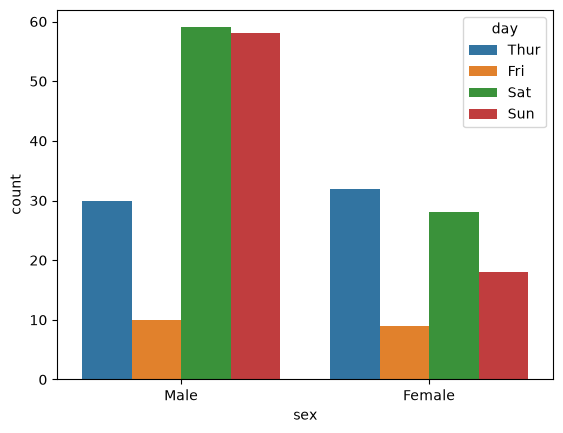

In [37]:
# countplot
sns.countplot(data=tips,x='sex',hue='day')

### Countplot (Frequency Bar Plot)

A **countplot** is a specialized categorical plot where the y-axis represents the **count of observations** in each category rather than computing an aggregated statistic for a second variable.
- It acts like a **histogram over a categorical variable** (instead of a continuous quantitative variable).

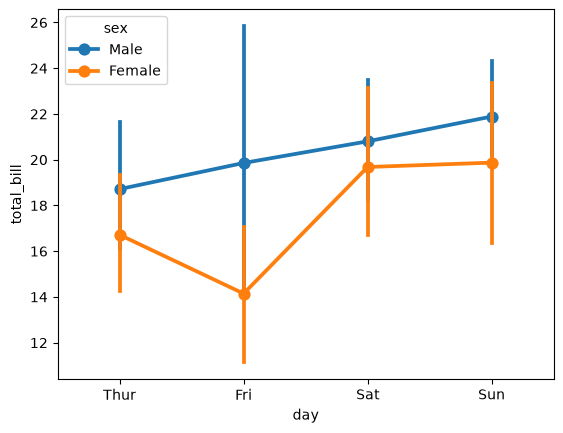

In [38]:
# pointplot
sns.pointplot(data=tips, x='day', y='total_bill', hue='sex')
plt.show()

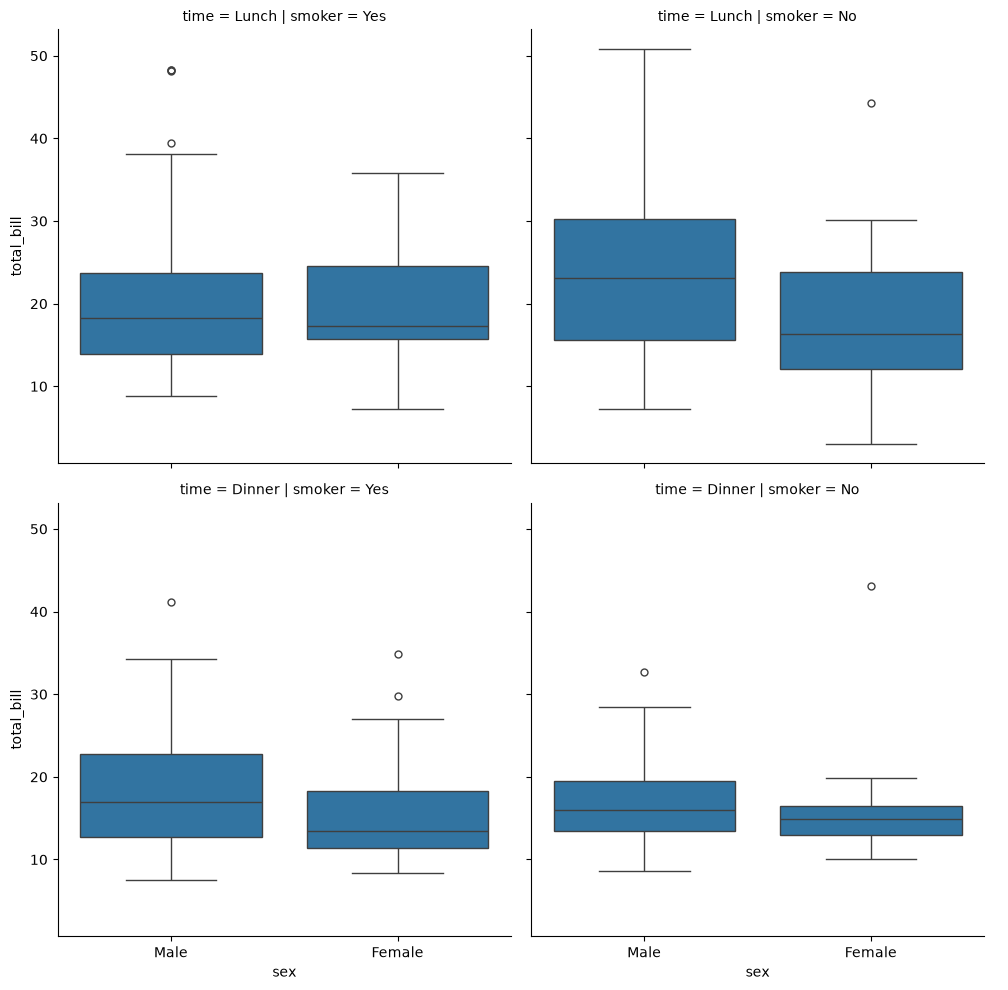

In [39]:
# faceting using catplot
sns.catplot(data=tips, x='sex',y='total_bill',col='smoker',kind='box',row='time')

### 4. Regression Plots

Regression plots estimate and visualize linear relationships between two continuous variables, plotting the best-fit line alongside confidence intervals.

#### Functions:
- **`sns.regplot()`** (Axes-level): Draws a scatter plot, computes a linear regression model ($y = \beta_0 + \beta_1 x$), and renders the regression line with a 95% bootstrap confidence interval band. *(Note: Does not support the `hue` parameter).*
- **`sns.lmplot()`** (Figure-level): Built on top of `regplot` and `FacetGrid`. Fully supports `hue`, `col`, and `row` parameters to fit and compare separate regression models across sub-categories.
- **`sns.residplot()`** (Axes-level): Evaluates model goodness-of-fit by plotting residuals ($e_i = y_i - \hat{y}_i$).
  - **Interpretation**: A random scatter around zero confirms linearity and constant variance (**homoscedasticity**); a curved or funnel pattern indicates non-linearity or heteroscedasticity.

<Axes: xlabel='total_bill', ylabel='tip'>

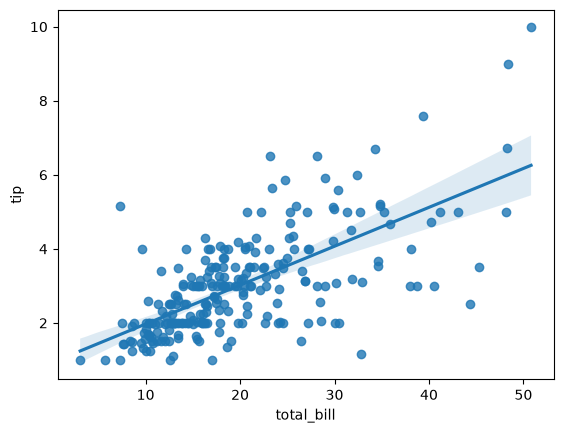

In [40]:
# axes level
# hue parameter is not available
sns.regplot(data=tips,x='total_bill',y='tip')

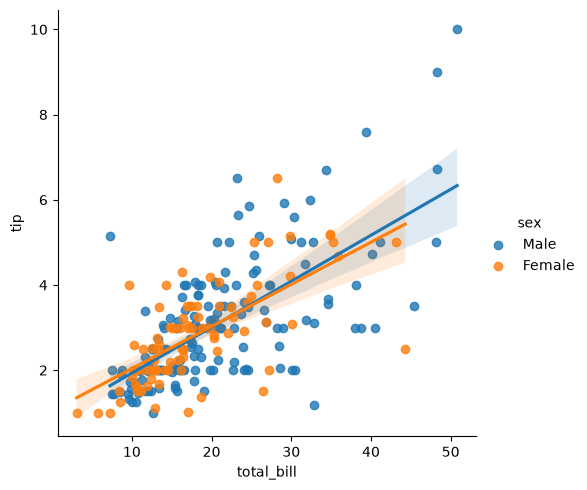

In [41]:
sns.lmplot(data=tips,x='total_bill',y='tip',hue='sex')

<Axes: xlabel='total_bill', ylabel='tip'>

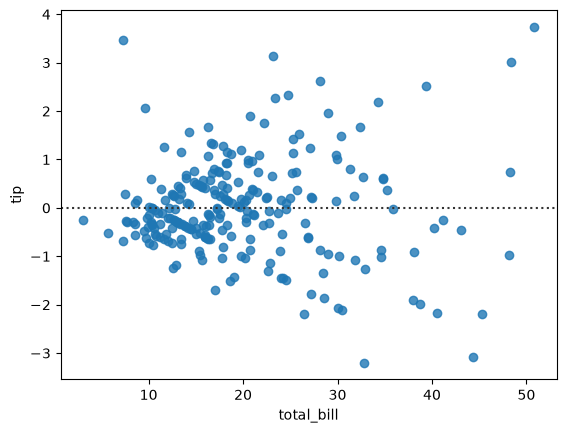

In [42]:
# residplot
sns.residplot(data=tips,x='total_bill',y='tip')

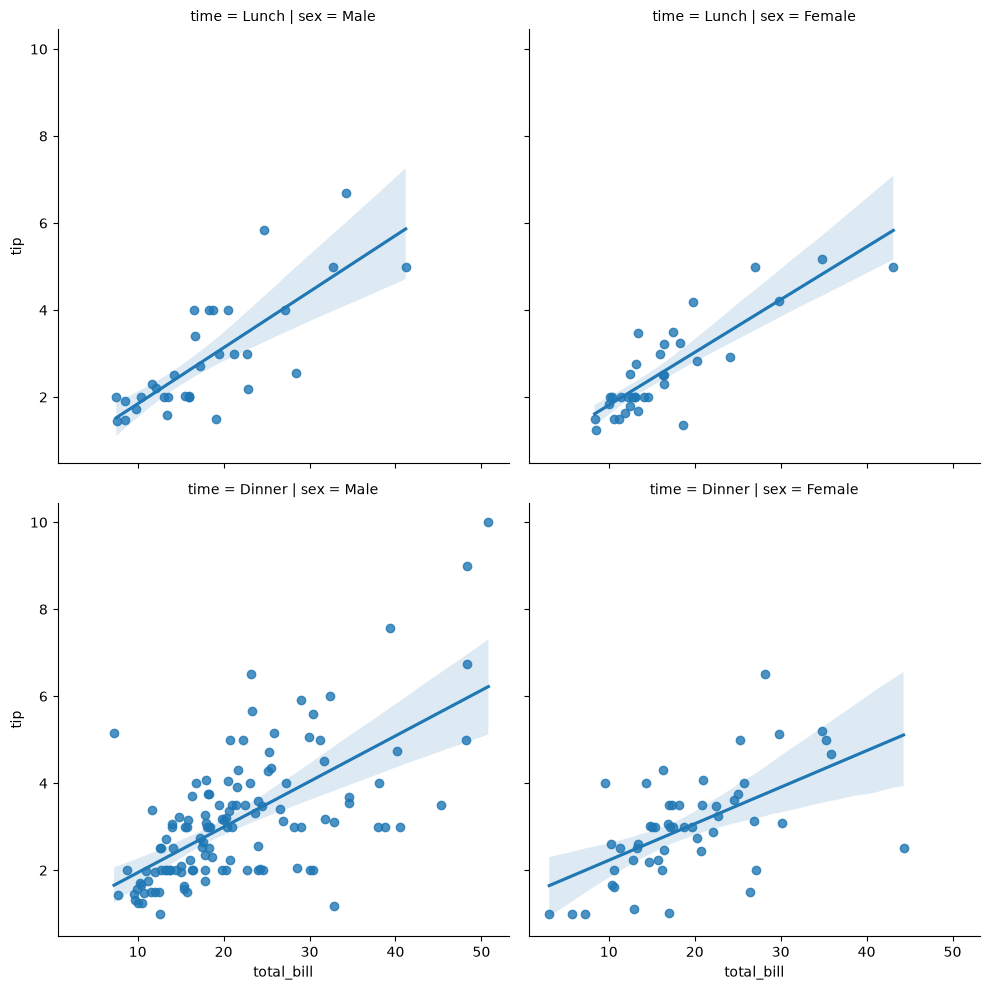

In [43]:
# lmplot with facets (col and row)
sns.lmplot(data=tips, x='total_bill', y='tip', col='sex', row='time')
plt.show()

### 5. Matrix Plots

Matrix plots visualize 2D tabular matrices as color-encoded heatmaps, where color hue and intensity represent value magnitudes. Ideal for correlation matrices and cross-tabulation pivot tables.

#### Functions:
- **`sns.heatmap()`**: Plots a 2D color matrix.
  - Key Parameters:
    - `annot=True`: Displays numerical values inside each cell.
    - `fmt`: Controls number formatting string (e.g. `fmt=".2f"`).
    - `cmap`: Sets the colormap palette (e.g. `"coolwarm"`, `"Blues"`, `"viridis"`).
    - `linewidths`: Adds spacing borders between adjacent cells.
- **`sns.clustermap()`**: Hierarchical clustering matrix.
  - Automatically reorders rows and columns based on statistical similarity and displays **dendrogram** tree diagrams on the outer margins.
  - Identifies natural clusters and groupings across multivariate data.

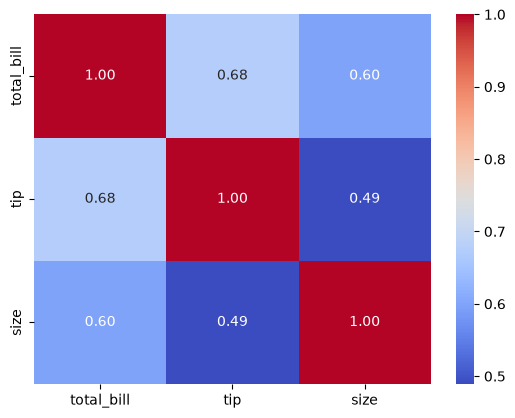

In [44]:
# Heatmap: correlation matrix
numeric_tips = tips.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_tips.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

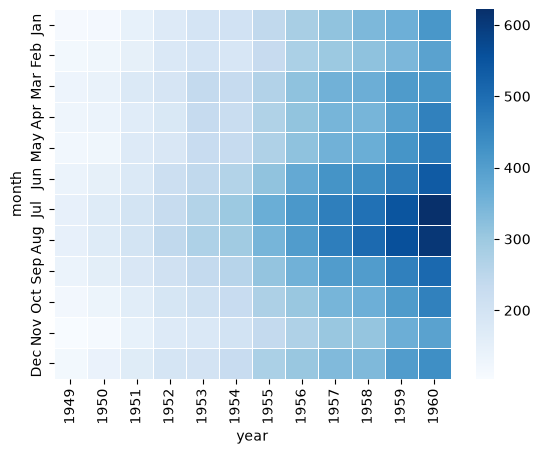

In [45]:
# Heatmap on Pivot Table using flights dataset
flights = sns.load_dataset('flights')
pivot_flights = flights.pivot_table(index='month', columns='year', values='passengers')
sns.heatmap(pivot_flights, cmap='Blues', linewidths=0.5)
plt.show()

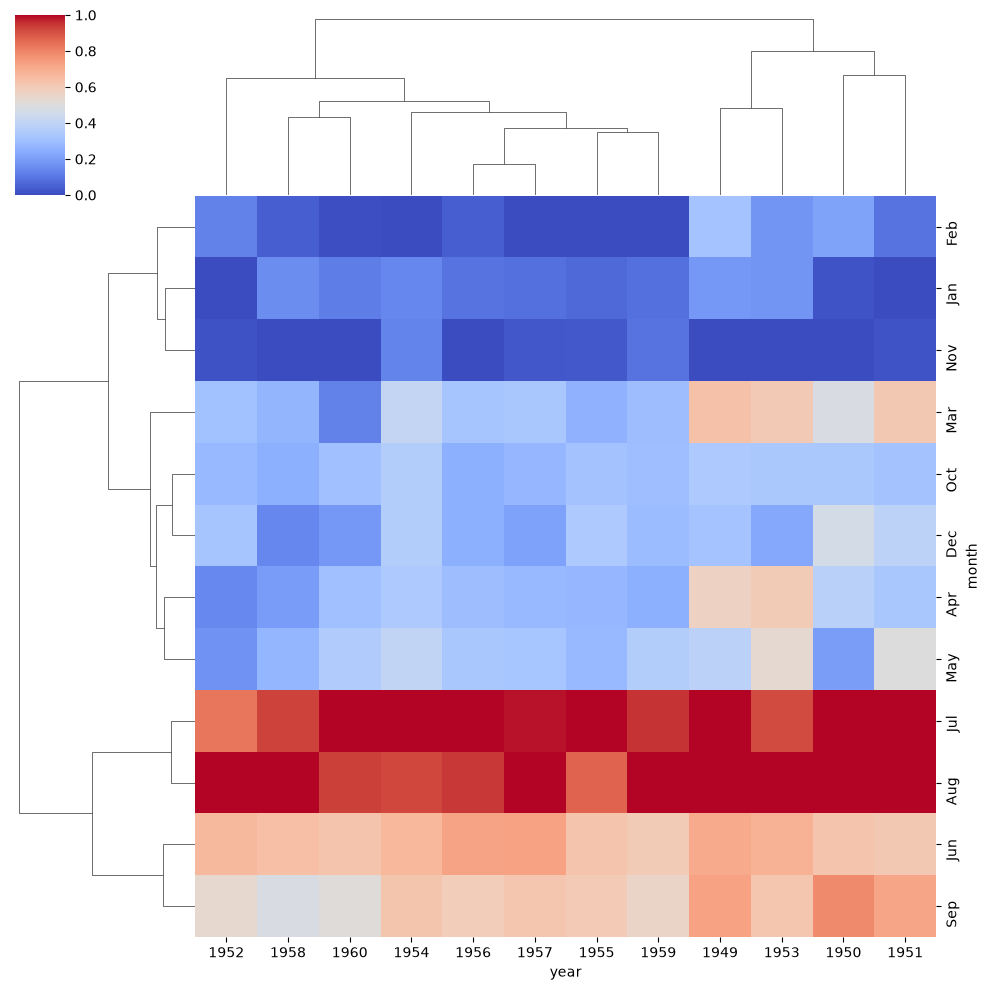

In [46]:
# Clustermap (hierarchical clustering on heatmap)
sns.clustermap(pivot_flights, cmap='coolwarm', standard_scale=1)
plt.show()

### 6. Multiplots (FacetGrid, PairGrid, JointGrid)

Multiplot grids are specialized layout classes for building multi-panel figures based on the structure of your dataset.

#### `sns.FacetGrid` (Multi-Panel Conditioning Grid)
A general-purpose multi-panel canvas mapping plotting functions across conditional subsets defined by `row`, `col`, and `hue`.
- **Workflow**:
  1. Initialize grid: `g = sns.FacetGrid(data, col="...", row="...", hue="...")`
  2. Map plot function: `g.map(sns.scatterplot, "x_col", "y_col")` or `g.map_dataframe(...)`
  3. Add legend & style: `g.add_legend()`

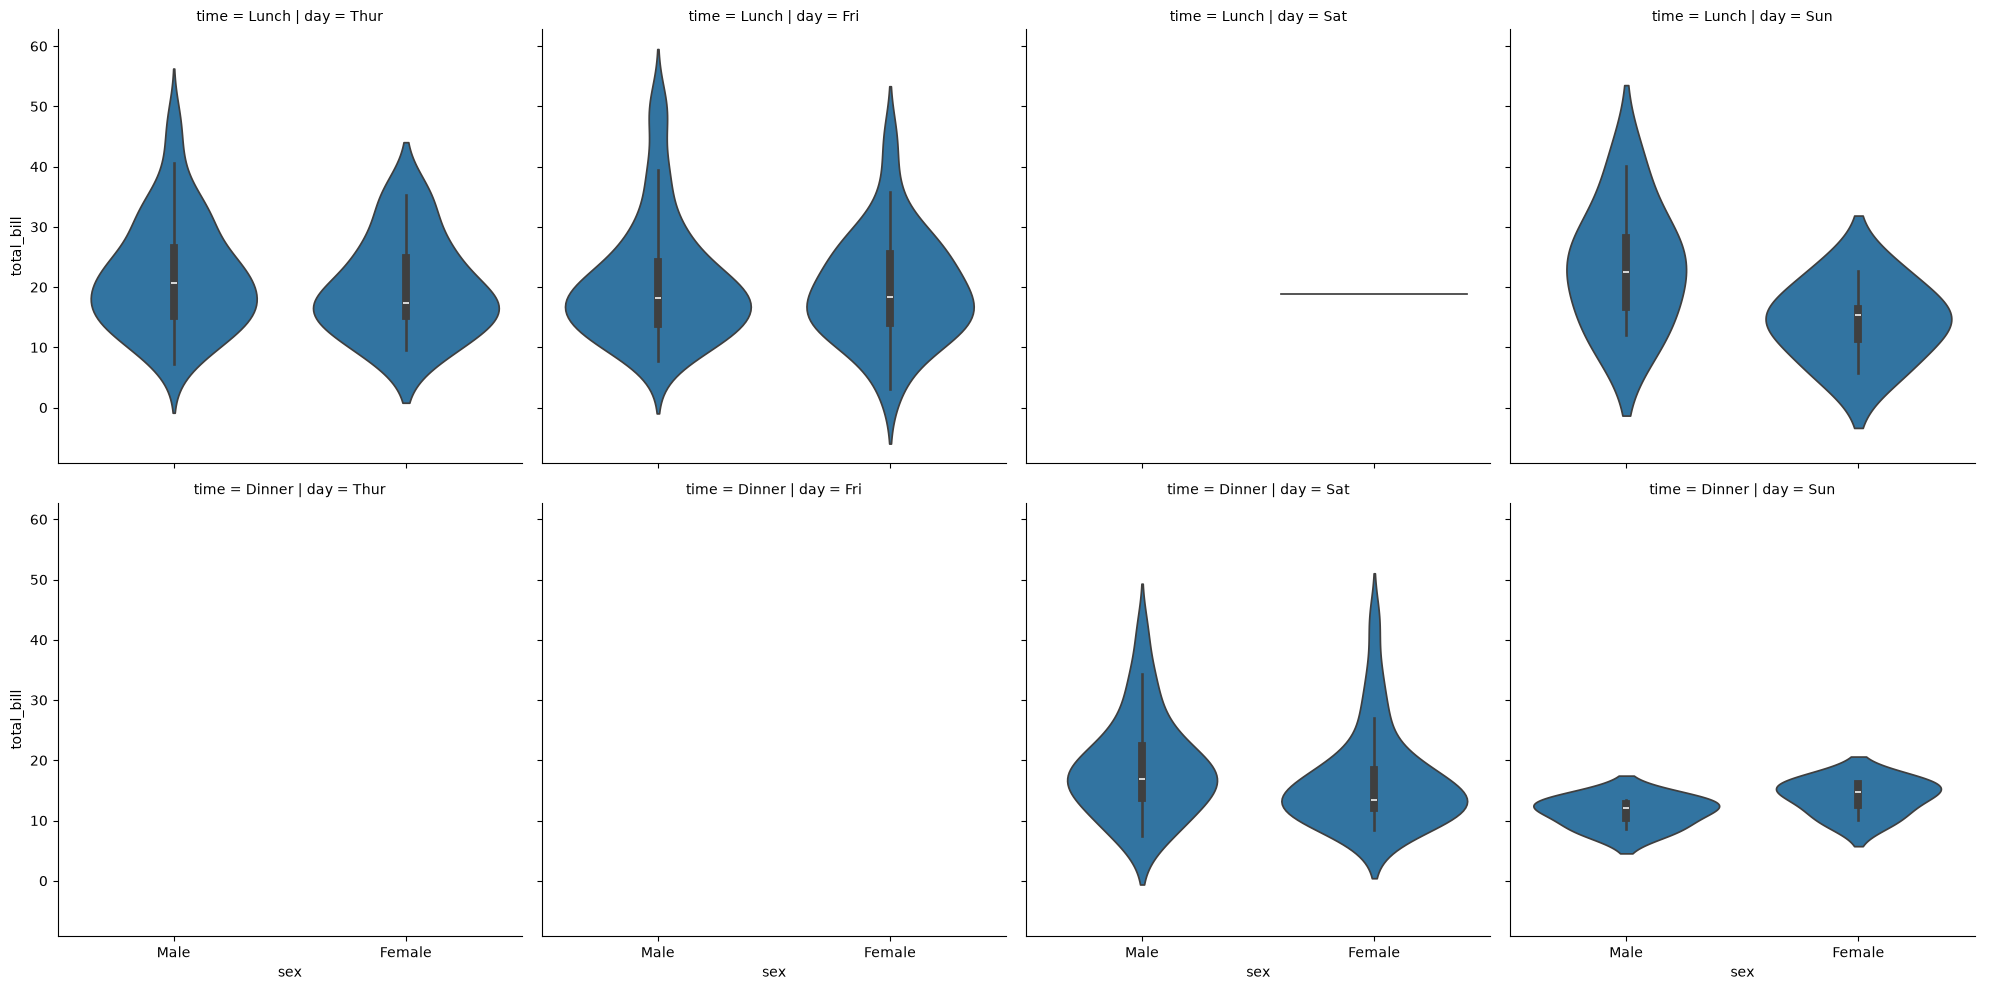

In [47]:
# figure level -> relplot -> displot -> catplot -> lmplot
sns.catplot(data=tips,x='sex',y='total_bill',kind='violin',col='day',row='time')

/Users/drishtisharma/Downloads/DSMP/.venv/lib/python3.14/site-packages/seaborn/axisgrid.py:718: UserWarning: Using the boxplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


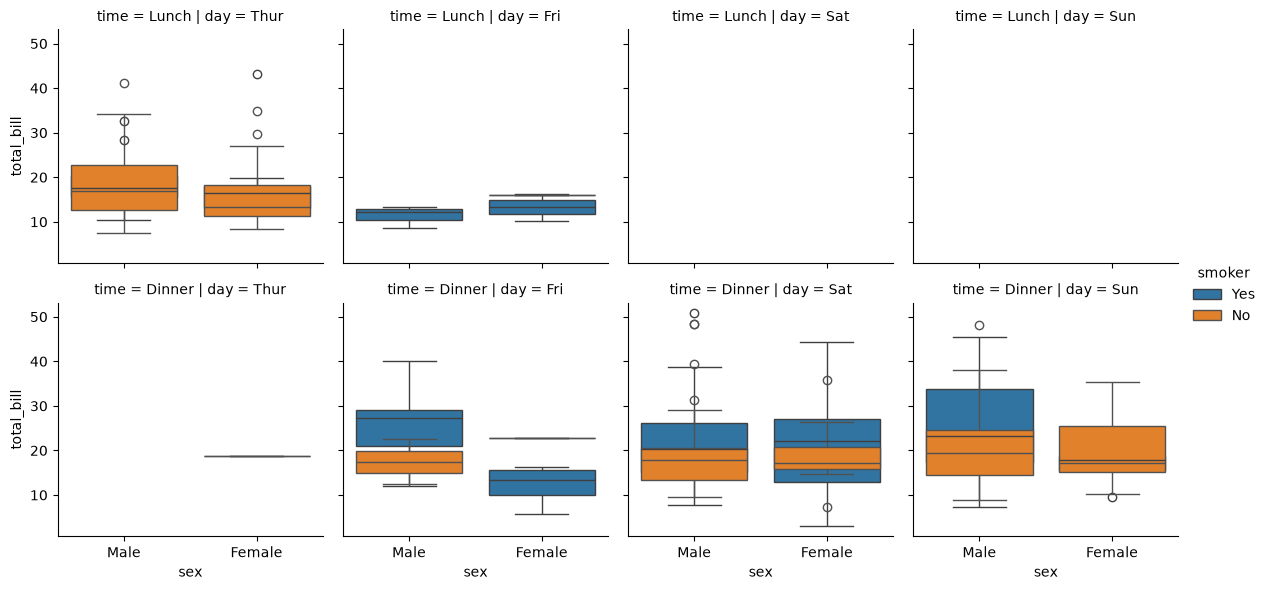

In [48]:
g = sns.FacetGrid(data=tips,col='day',row='time',hue='smoker')
g.map(sns.boxplot,'sex','total_bill')
g.add_legend()

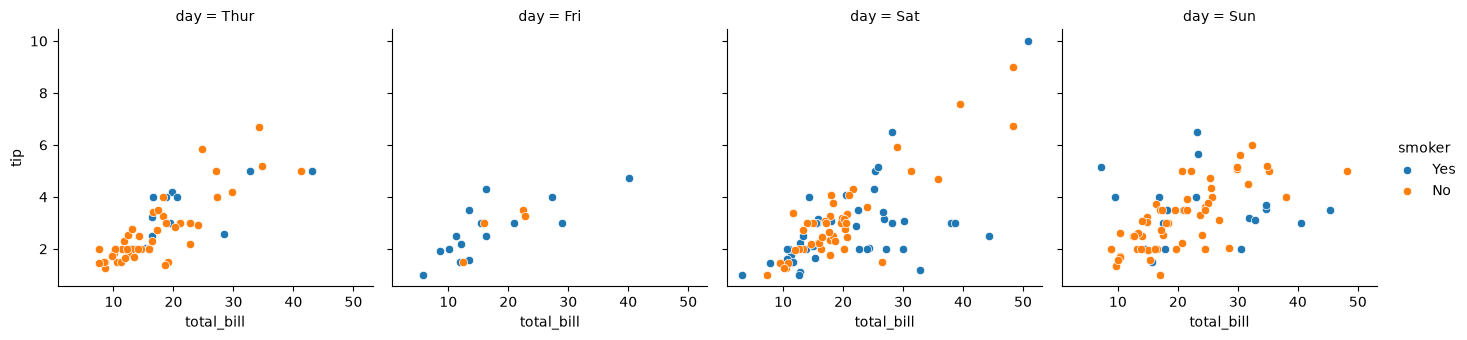

In [49]:
# FacetGrid with height and aspect
g = sns.FacetGrid(data=tips, col='day', hue='smoker', height=3.5, aspect=1)
g.map(sns.scatterplot, 'total_bill', 'tip')
g.add_legend()
plt.show()

### Plotting Pairwise Relationship (PairGrid Vs. Pairplot)

- **`sns.pairplot()`**: High-level convenience function rendering pairwise scatter plots and diagonal histograms across all numerical columns in a single call.
- **`sns.PairGrid`**: Fully customizable pairwise matrix. Allows different plot types across grid regions:
  - `g.map_diag()`: Diagonal plots (univariate distribution: `sns.histplot`, `sns.kdeplot`, `sns.boxplot`).
  - `g.map_offdiag()`: Off-diagonal plots (bivariate relationships).
  - `g.map_upper()` / `g.map_lower()`: Differentiate upper vs. lower triangular halves.
  - `vars=[...]`: Restricts visualization to specific columns.

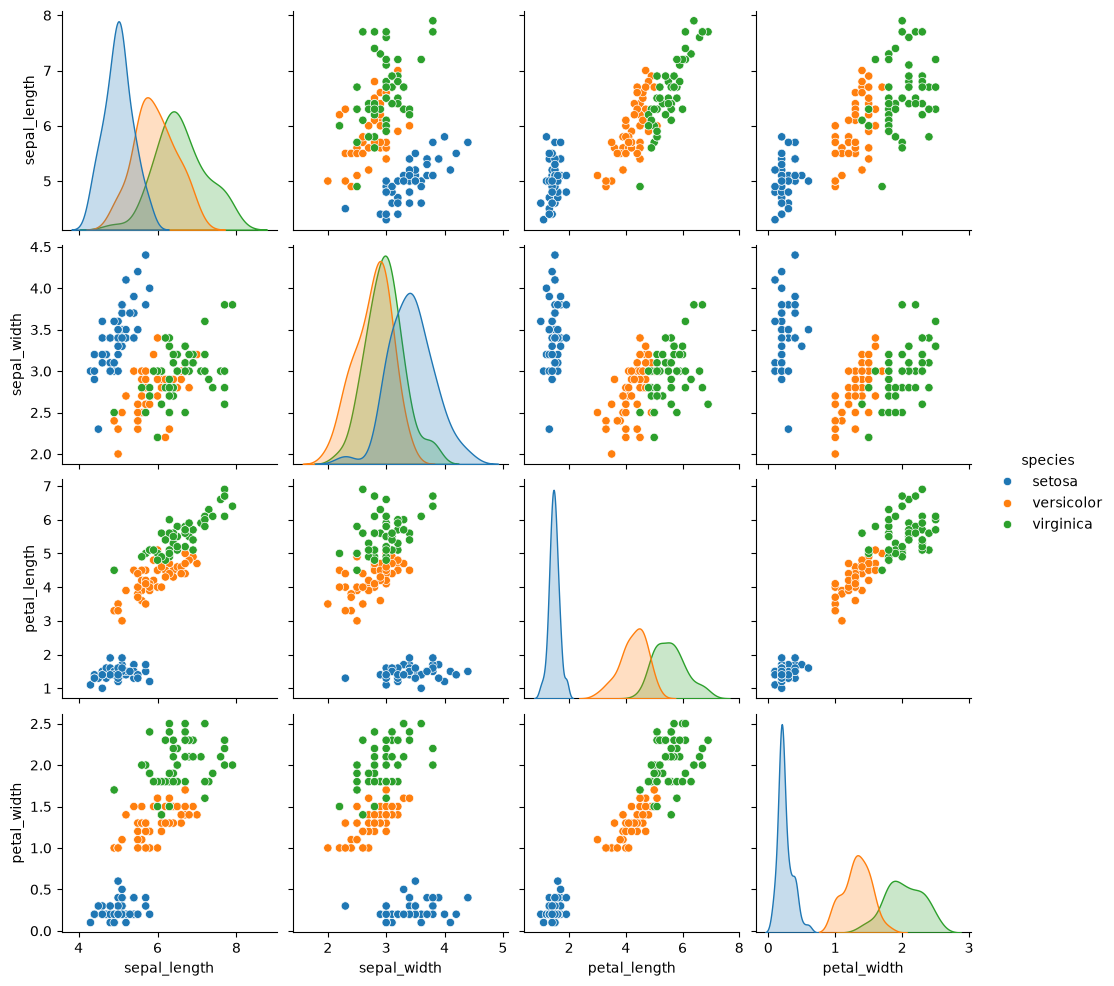

In [50]:
sns.pairplot(iris,hue='species')

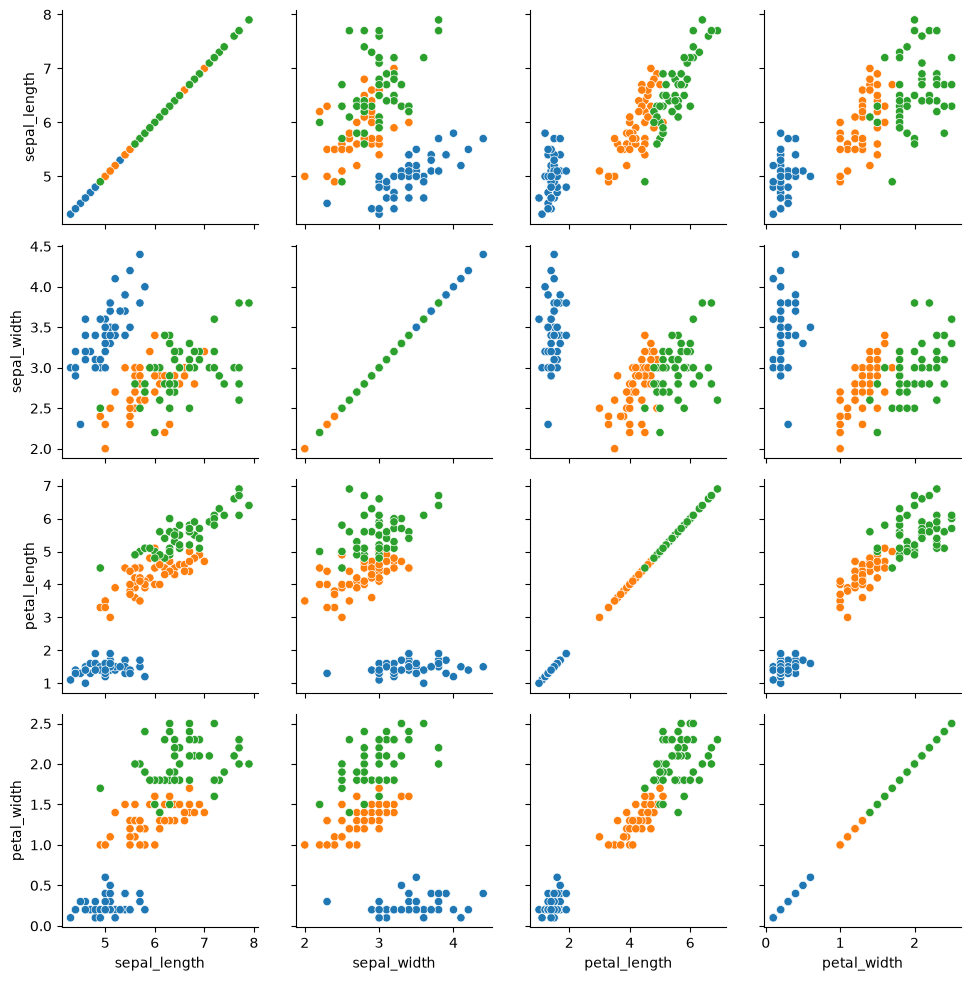

In [51]:
# pair grid
g = sns.PairGrid(data=iris,hue='species')
# g.map
g.map(sns.scatterplot)

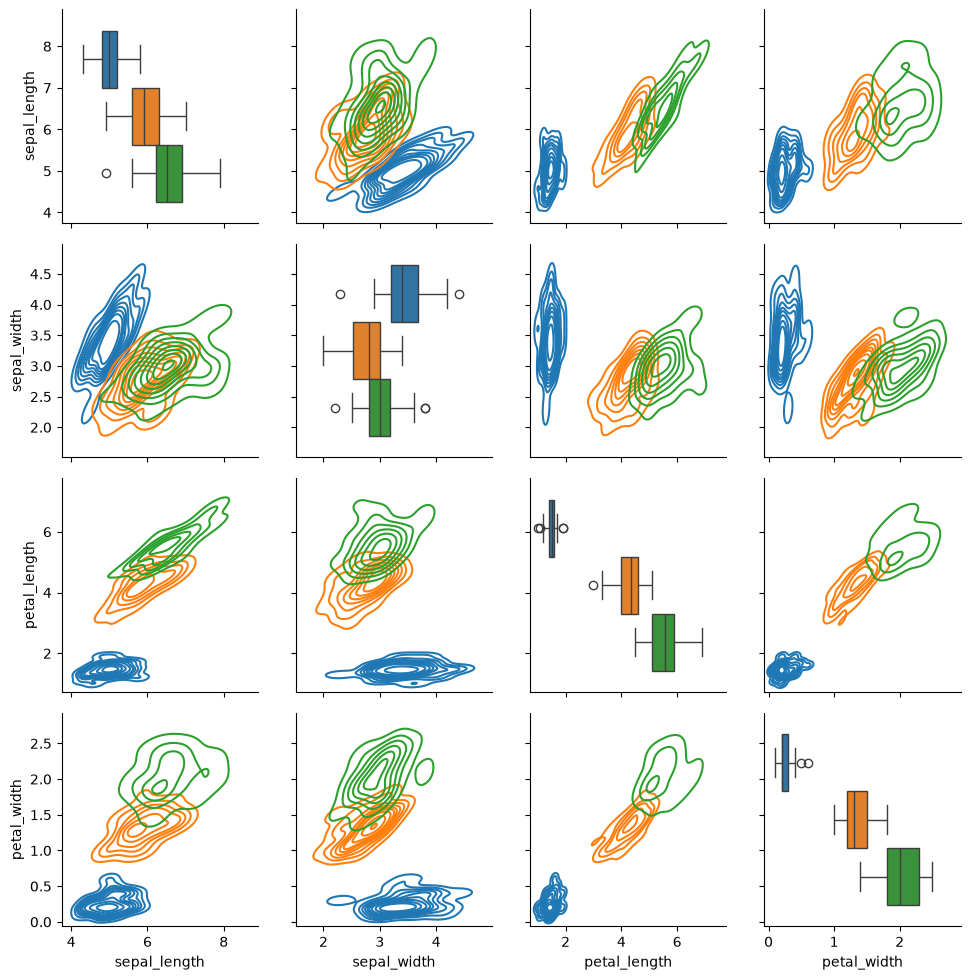

In [52]:
# map_diag -> map_offdiag
g = sns.PairGrid(data=iris,hue='species')
g.map_diag(sns.boxplot)
g.map_offdiag(sns.kdeplot)

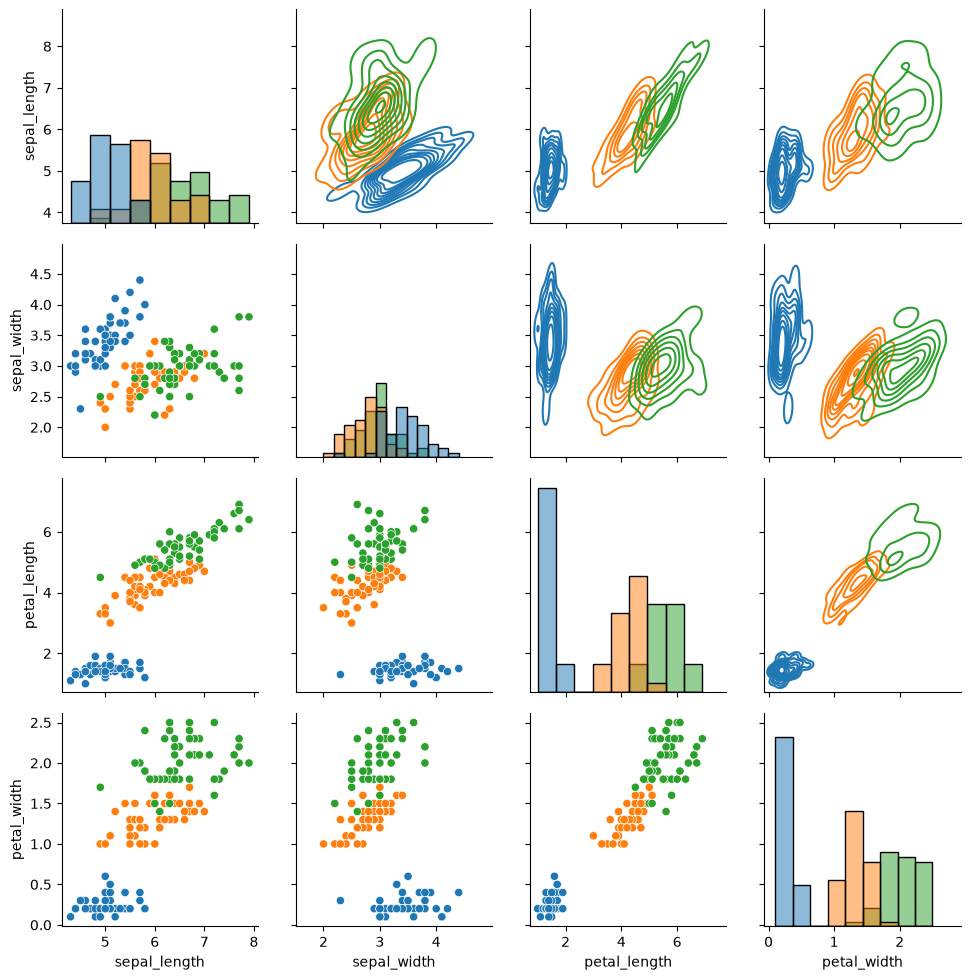

In [53]:
# map_diag -> map_upper -> map_lower
g = sns.PairGrid(data=iris,hue='species')
g.map_diag(sns.histplot)
g.map_upper(sns.kdeplot)
g.map_lower(sns.scatterplot)

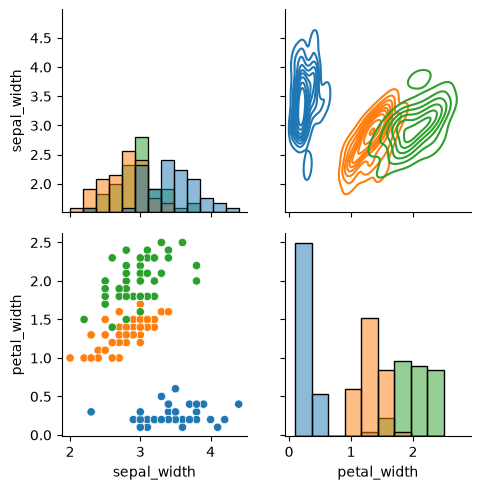

In [54]:
# vars
g = sns.PairGrid(data=iris,hue='species',vars=['sepal_width','petal_width'])
g.map_diag(sns.histplot)
g.map_upper(sns.kdeplot)
g.map_lower(sns.scatterplot)

### JointGrid Vs. Jointplot

- **`sns.jointplot()`**: High-level figure pairing a central bivariate plot (`kind="scatter" | "kde" | "hist" | "reg" | "hex"`) with marginal univariate distributions on the top and right margins.
- **`sns.JointGrid`**: Granular constructor giving independent control over the central plot and marginal axes (`g.plot()`, `g.plot_joint()`, `g.plot_marginals()`).

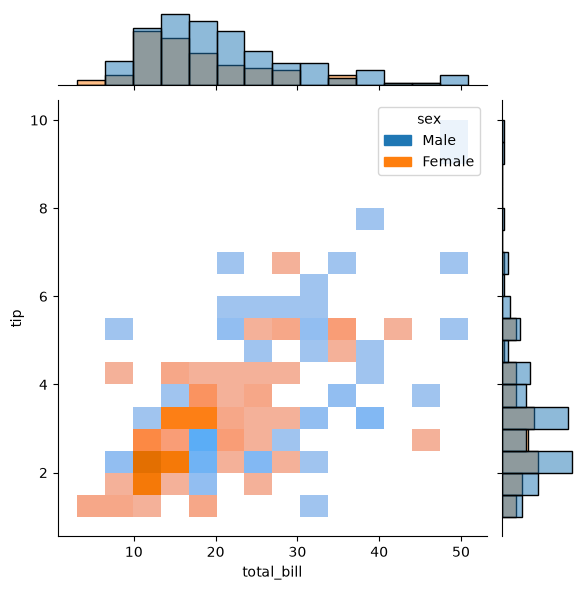

In [55]:
sns.jointplot(data=tips,x='total_bill',y='tip',kind='hist',hue='sex')

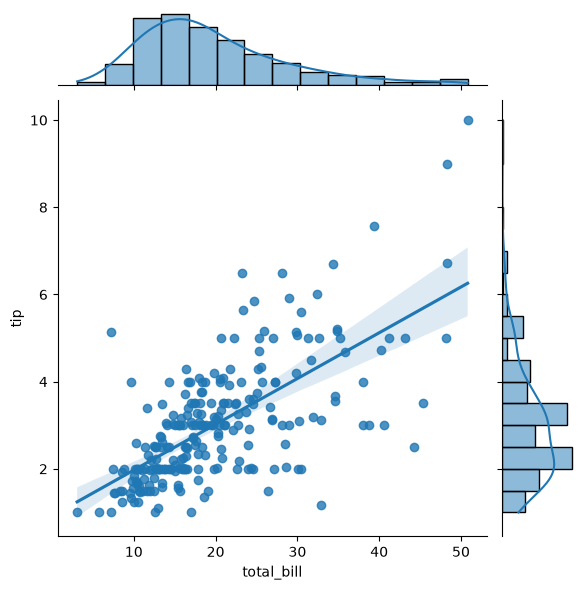

In [56]:
# jointplot with regression line
sns.jointplot(data=tips, x='total_bill', y='tip', kind='reg')
plt.show()

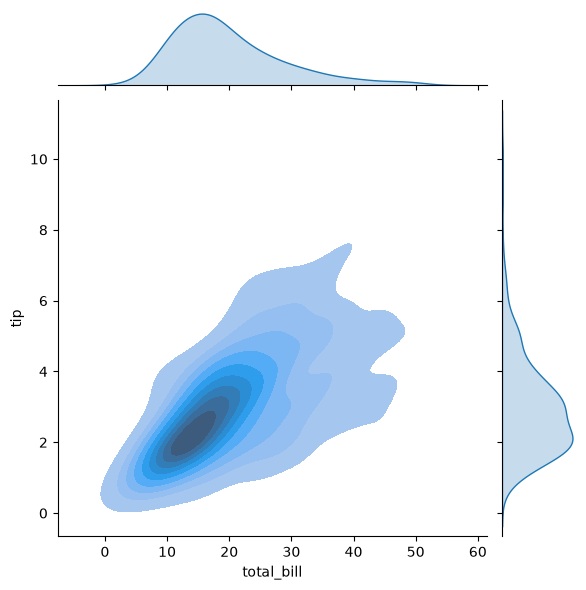

In [57]:
# jointplot with 2D KDE
sns.jointplot(data=tips, x='total_bill', y='tip', kind='kde', fill=True)
plt.show()

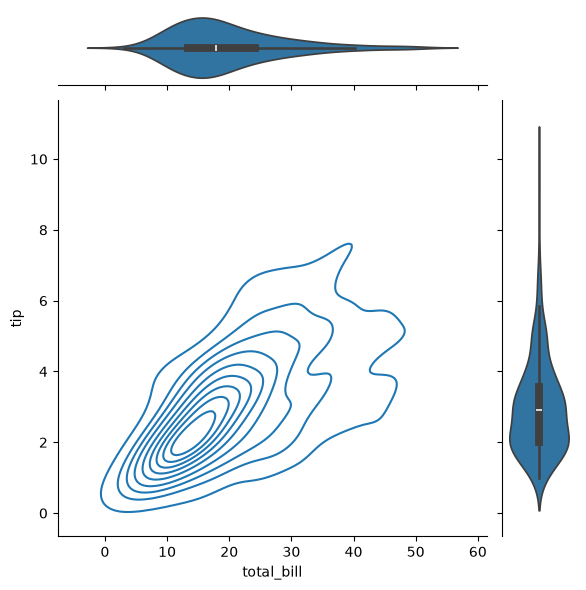

In [58]:
g = sns.JointGrid(data=tips,x='total_bill',y='tip')
g.plot(sns.kdeplot,sns.violinplot)

### 7. Utility Functions, Themes & Styling

Seaborn provides utilities for inspecting sample datasets and customizing plot themes, scales, and palettes globally or locally.

#### Utilities:
- **`sns.get_dataset_names()`**: Lists all built-in datasets hosted in Seaborn online repository (e.g., `tips`, `iris`, `flights`, `planets`, `titanic`).
- **`sns.load_dataset(name)`**: Loads a built-in dataset into a clean Pandas DataFrame.

#### Styling & Themes:
- **5 Built-in Grid Themes**:
  - `"darkgrid"` (default: grey background with white grid)
  - `"whitegrid"` (white background with grey grid lines – best for plots with many points)
  - `"dark"` (solid grey background without grid)
  - `"white"` (clean white background without grid)
  - `"ticks"` (white background with tick marks on axes)
- **Key Functions**:
  - `sns.set_theme(style="...", palette="...", font_scale=...)`: Sets global visualization defaults.
  - `sns.despine(top=True, right=True)`: Removes unnecessary top and right axis spines for a cleaner aesthetic.
  - `sns.color_palette()`: Customizes categorical and sequential color maps (`"deep"`, `"muted"`, `"pastel"`, `"bright"`, `"dark"`, `"colorblind"`).

In [59]:
# get dataset names
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [60]:
# load dataset
sns.load_dataset('planets')

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300000,7.10,77.40,2006
1,Radial Velocity,1,874.774000,2.21,56.95,2008
2,Radial Velocity,1,763.000000,2.60,19.84,2011
3,Radial Velocity,1,326.030000,19.40,110.62,2007
4,Radial Velocity,1,516.220000,10.50,119.47,2009
...,...,...,...,...,...,...
1030,Transit,1,3.941507,NaN,172.00,2006
1031,Transit,1,2.615864,NaN,148.00,2007
1032,Transit,1,3.191524,NaN,174.00,2007
1033,Transit,1,4.125083,NaN,293.00,2008


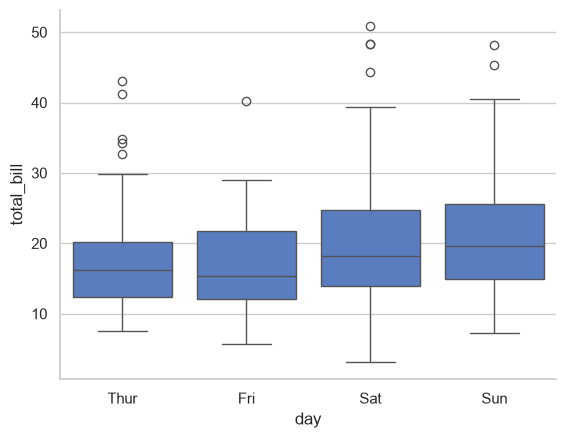

In [61]:
# Seaborn Styling, Themes, and Palettes
# Available themes/styles: darkgrid, whitegrid, dark, white, ticks
sns.set_theme(style='whitegrid', palette='muted')
sns.boxplot(data=tips, x='day', y='total_bill')
sns.despine()
plt.show()

# Reset to default seaborn theme
sns.set_theme()